In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("/project/results/timings.csv")
avl = df[(df.index_type == "avl_tree") & (df.code_version.astype(str).str.startswith("f6f773e"))] #filters the results down to the rows for incident repor

In [3]:
e1 = avl[(avl.experiment == "E1_build_track_id") & (avl.operation == "build")]                                                                                                
e5 = avl[(avl.experiment == "E5_insert_order") & (avl.operation == "build")]

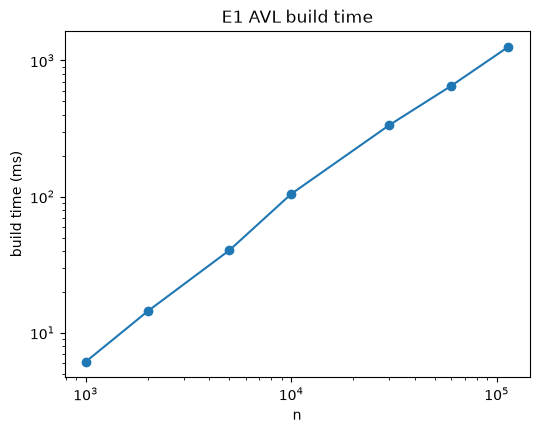

In [4]:
fig, ax = plt.subplots(figsize=(6, 4.5))                                                                                                                                      
med = e1.groupby("n_keys")["total_ns"].median() / 1e6                                                                                                                         
ax.plot(med.index, med.values, "o-")                                                                                                                                          
ax.set(xscale="log", yscale="log", xlabel="n", ylabel="build time (ms)", title="E1 AVL build time")                                                                           
fig.savefig("inc03_AVL.png", dpi=150)   

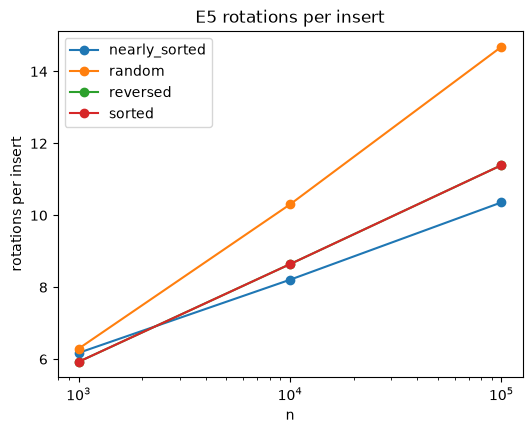

In [5]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for order, g in e5.groupby("insert_order"):
    r = g.groupby("n_keys")["rotations"].median()
    ax.plot(r.index, r.values / r.index, "o-", label=order)
ax.set(xscale="log", xlabel="n", ylabel="rotations per insert", title="E5 rotations per insert")
ax.legend()
fig.savefig("inc03_AVLrotations.png", dpi=150)

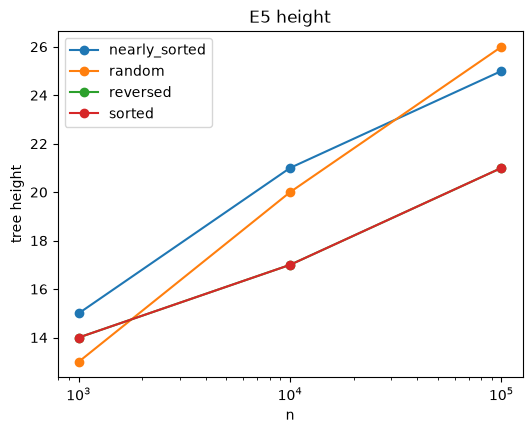

In [6]:
fig, ax = plt.subplots(figsize=(6, 4.5))
for order, g in e5.groupby("insert_order"):
    h = g.groupby("n_keys")["height"].median()
    ax.plot(h.index, h.values, "o-", label=order)
ax.set(xscale="log", xlabel="n", ylabel="tree height", title="E5 height")
ax.legend()

fig.savefig("inc03_AVLheight.png", dpi=150)


In [7]:
before_table = e5.groupby(["insert_order", "n_keys"]).agg(                                                                                                                    
    rotations=("rotations", "median"), height=("height", "median")).reset_index()                                                                                             
before_table["rot_per_insert"] = before_table.rotations / before_table.n_keys                                                                                                 
before_table["log2_n"] = np.log2(before_table.n_keys).round(1)                                                                                                                
before_table 

,insert_order,n_keys,rotations,height,rot_per_insert,log2_n
0,nearly_sorted,1000,6176.0,15.0,6.17600,10.0
1,nearly_sorted,10000,82091.0,21.0,8.20910,13.3
2,nearly_sorted,100000,1035937.0,25.0,10.35937,16.6
3,random,1000,6295.0,13.0,6.29500,10.0
4,random,10000,103049.0,20.0,10.30490,13.3
5,random,100000,1468640.0,26.0,14.68640,16.6
6,reversed,1000,5928.0,14.0,5.92800,10.0
7,reversed,10000,86432.0,17.0,8.64320,13.3
8,reversed,100000,1139341.0,21.0,11.39341,16.6
9,sorted,1000,5928.0,14.0,5.92800,10.0


In [8]:
AFTER = "549f076"                                                                                                                                                           
after = df[(df.index_type == "avl_tree") & (df.code_version.astype(str).str.startswith(AFTER))]                                                                               
e1_after = after[(after.experiment == "E1_build_track_id") & (after.operation == "build")]                                                                                    
e5_after = after[(after.experiment == "E5_insert_order") & (after.operation == "build")]        

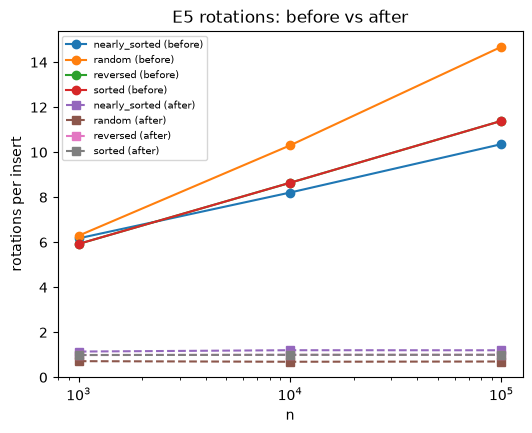

In [9]:
fig, ax = plt.subplots(figsize=(6, 4.5))                                                                                                                                      
for label, data, style in [("before", e5, "o-"), ("after", e5_after, "s--")]:                                                                                                 
    for order, g in data.groupby("insert_order"):                                                                                                                             
        r = g.groupby("n_keys")["rotations"].median()                                                                                                                         
        ax.plot(r.index, r.values / r.index, style, label=f"{order} ({label})")                                                                                                                                                                                                                       
ax.set(xscale="log", xlabel="n", ylabel="rotations per insert", title="E5 rotations: before vs after")                                                                        
ax.legend(fontsize=7)                                                                                                                                                         
fig.savefig("inc03_rotations.png", dpi=150)

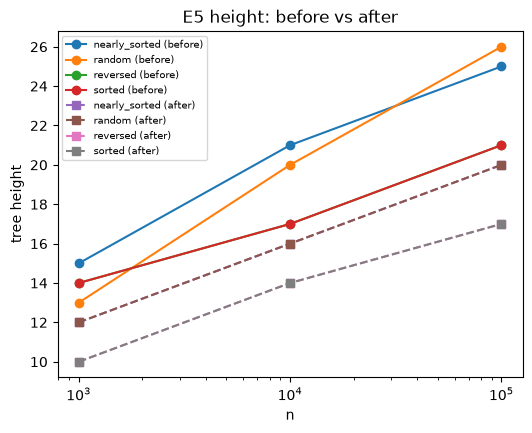

In [10]:
fig, ax = plt.subplots(figsize=(6, 4.5))                                                                                                                                      
for label, data, style in [("before", e5, "o-"), ("after", e5_after, "s--")]:                                                                                                 
    for order, g in data.groupby("insert_order"):                                                                                                                             
        h = g.groupby("n_keys")["height"].median()                                                                                                                            
        ax.plot(h.index, h.values, style, label=f"{order} ({label})")                                                                                                         
ax.set(xscale="log", xlabel="n", ylabel="tree height", title="E5 height: before vs after")                                                                                    
ax.legend(fontsize=7)                                                                                                                                                         
fig.savefig("inc03_height.png", dpi=150)

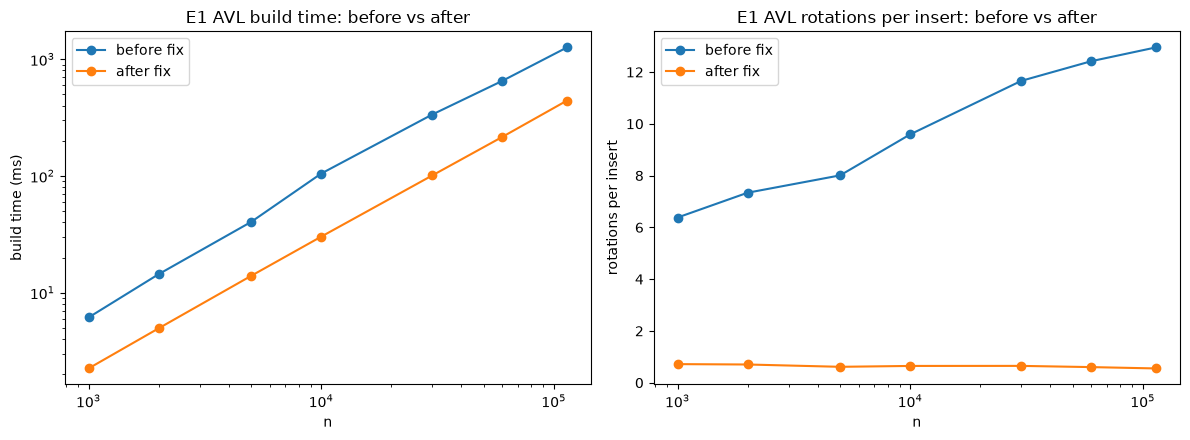

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for label, data in [("before fix", e1), ("after fix", e1_after)]:
    med = data.groupby("n_keys").agg(ms=("total_ns", lambda s: s.median() / 1e6),
                                     rot=("rotations", "median"))
    axes[0].plot(med.index, med.ms, "o-", label=label)
    axes[1].plot(med.index, med.rot / med.index, "o-", label=label)
axes[0].set(xscale="log", yscale="log", xlabel="n", ylabel="build time (ms)", title="E1 AVL build time: before vs after")
axes[1].set(xscale="log", xlabel="n", ylabel="rotations per insert", title="E1 AVL rotations per insert: before vs after")
for ax in axes:
    ax.legend()
fig.tight_layout()
fig.savefig("inc03_build.png", dpi=150)